Importamos las librerías y cargamos las tablas que utilizaremos.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

import kagglehub
from pathlib import Path


# Obtenemos la carpeta del dataset.
path = kagglehub.dataset_download(
    "gulsahdemiryurek/harry-potter-dataset"
)

# Cargamos personajes y pociones.
df_personajes = pd.read_csv(Path(path) / "Characters.csv", sep=";")
df_pociones = pd.read_csv(Path(path) / "Potions.csv", sep=";")
df_hechizos = pd.read_csv(Path(path) / "Spells.csv", sep= ";")

## Gráfico de barras: personajes por casa de Hogwarts

Seleccionamos los personajes con una de las cuatro casas registrada
y contamos cuántos pertenecen a cada una.

El eje horizontal mostrará las casas y el vertical mostrará
el número de personajes incluidos en el dataset.

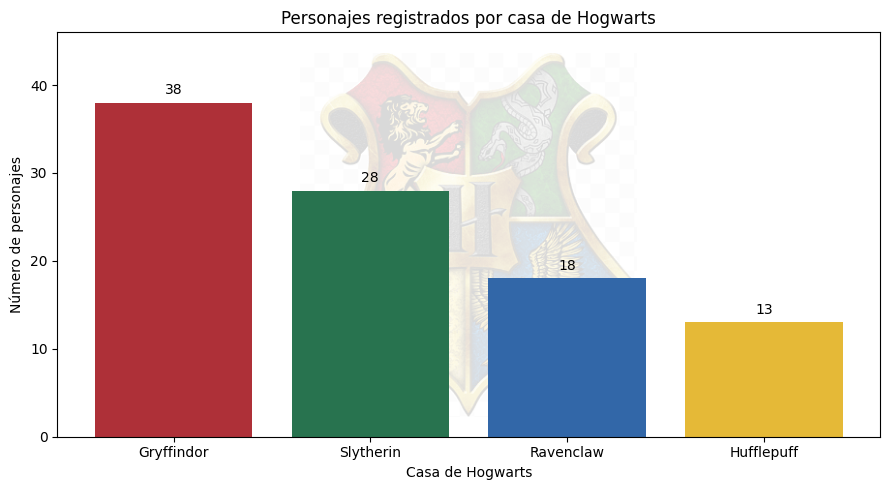

In [ ]:
from urllib.request import urlopen
from PIL import Image
import numpy as np

# Cargamos el escudo desde su dirección directa en GitHub.
url_escudo = "https://raw.githubusercontent.com/emontalban/RETO-INDIVIDUAL-DETECTIVE-DE-DATOS/main/images/hogwarts.png"

with urlopen(url_escudo) as respuesta:
    escudo = np.array(Image.open(respuesta).convert("RGBA"))

# Seleccionamos únicamente las cuatro casas de Hogwarts.
casas_hogwarts = [
    "Gryffindor",
    "Slytherin",
    "Ravenclaw",
    "Hufflepuff"
]

df_hogwarts = df_personajes[
    df_personajes["House"].isin(casas_hogwarts)
]

# Contamos los personajes en el orden de las casas.
personajes_por_casa = (
    df_hogwarts["House"]
    .value_counts()
    .reindex(casas_hogwarts, fill_value=0)
)

# Creamos la figura y su ejes.
# fig: representa la figura completa.
# ax: representa los ejes donde dibujamos las barras.
fig, ax = plt.subplots(figsize=(9, 5))

# Colocamos el escudo centrado y conservamos sus proporciones.
fondo = ax.inset_axes([0.2, 0.05, 0.6, 0.9], zorder=0) #Los cuatro números indican la posición 
                                                        # izquierda, la posición inferior, el ancho y el alto, expresados
                                                        # como proporciones del área del gráfico.
fondo.imshow(escudo, alpha=0.15) # muestra la imagen con un 15 % de opacidad
fondo.axis("off") # oculta los ejes del área donde está el escudo.


# Dibujamos las barras por delante del escudo.
barras = ax.bar(
    personajes_por_casa.index,
    personajes_por_casa.values,
    color=["#AE3038", "#28734F", "#3267A8", "#E5B937"],
    zorder=2 # coloca las barras por delante del área del escudo
)

# Añadimos los números encima de las barras.
ax.bar_label(barras, padding=4)

# Añadimos título y nombres de los ejes.
ax.set_title("Personajes registrados por casa de Hogwarts") 
ax.set_xlabel("Casa de Hogwarts")
ax.set_ylabel("Número de personajes")

# Dejamos espacio por encima de las barras.
ax.set_ylim(0, personajes_por_casa.max() + 8)

# Ajustamos los espacios y mostramos el gráfico.
plt.tight_layout() # ajusta los espacios para evitar que se recorten los títulos y las etiquetas.
plt.show()

### Interpretación del gráfico: personajes por casa de Hogwarts

Gryffindor es la casa con más personajes registrados, con 38.
Le siguen Slytherin, con 28; Ravenclaw, con 18; y Hufflepuff, con 13.

La altura de las barras permite comparar las cantidades y muestra
una diferencia de 25 personajes entre Gryffindor y Hufflepuff.

El gráfico incluye los 97 personajes que tienen una de las cuatro
casas de Hogwarts registrada. Se excluyen los personajes sin casa
registrada y los asociados a otras escuelas.



##  Gráfico circular: dificultad de las pociones

Representamos cómo se distribuyen los niveles de dificultad entre
las pociones que tienen ese dato registrado.

Solo 25 de las 72 pociones disponen de esta información. Las otras
47 quedan fuera del gráfico.

Limpiamos los espacios de las etiquetas y contamos las pociones
de cada nivel antes de dibujarlo.

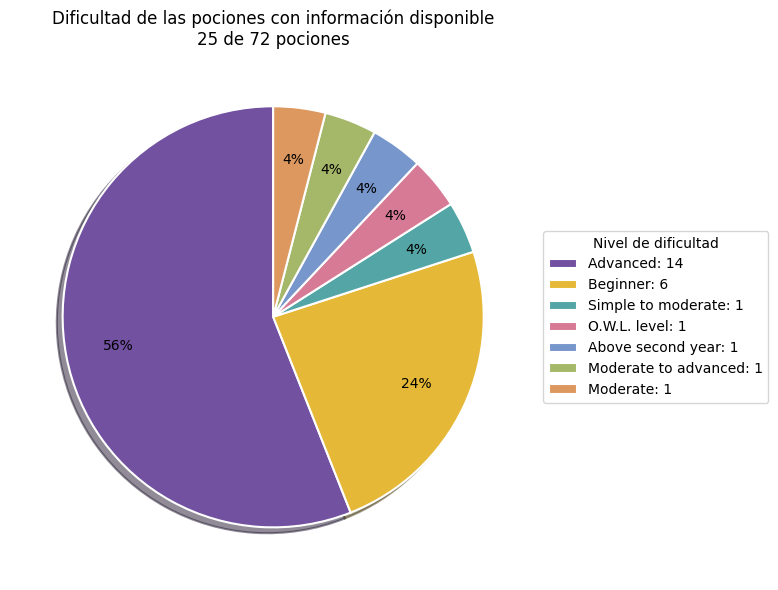

In [ ]:
# Limpiamos los espacios de los niveles de dificultad.
dificultades_limpias = (
    df_pociones["Difficulty level"]
    .str.replace("\xa0", " ", regex=False)
    .str.strip()
)

# Contamos cada nivel. value_counts() excluye los valores ausentes.
pociones_por_dificultad = dificultades_limpias.value_counts()

# Creamos la figura y los ejes.
fig, ax = plt.subplots(figsize=(10, 6))

# Dibujamos el gráfico circular.
sectores, textos, porcentajes = ax.pie(
    pociones_por_dificultad.values,
    colors=[
        "#7251A1", "#E5B937", "#54A6A6", "#D77A96",
        "#7796CB", "#A5B86A", "#DD9860"
    ],
    autopct="%1.0f%%", # muestra los porcentajes sin decimales.
    startangle=90, # sitúa el inicio del primer sector en la parte superior.
    pctdistance=0.75, #coloca los porcentajes al 75 % del radio
    shadow=True,  # Añade una sombra para dar sensación de relieve.
    wedgeprops={"edgecolor": "white", "linewidth": 1.5} #configura el aspecto de los sectores. En este caso, añade bordes blancos de grosor 1.5.
)

# Colocamos las categorías y sus cantidades en una leyenda.
etiquetas = [
    f"{nivel}: {cantidad}"
    for nivel, cantidad in pociones_por_dificultad.items()
]

ax.legend(
    sectores,
    etiquetas,
    title="Nivel de dificultad",
    loc="center left",
    bbox_to_anchor=(1, 0.5) #junto con loc="center left", coloca la
                            # leyenda a la derecha del gráfico, centrada verticalmente.
)

# Añadimos el título y aclaramos qué datos se representan.
ax.set_title(
    "Dificultad de las pociones con información disponible\n"
    f"{pociones_por_dificultad.sum()} de {len(df_pociones)} pociones"
)

# Conservamos la forma circular y ajustamos la presentación.
ax.set_aspect("equal") # mantiene la forma circular del gráfico.
plt.tight_layout()
plt.show()

### Interpretación del gráfico: dificultad de las pociones

Advanced ocupa el sector más grande: representa 14 de las 25 pociones
con dificultad registrada, el 56 %.

Beginner representa 6 pociones, el 24 %. Las otras cinco categorías
tienen una poción cada una y representan un 4 % individualmente.

El gráfico permite observar la distribución de las dificultades
conocidas, pero no describe la dificultad de las 72 pociones:
47 no tienen ese dato registrado.

Por tanto, no podemos afirmar que la mayoría de todas las pociones
del dataset sean avanzadas.